# Variance Decomposition Calculations and plots
This notebook is for the AR-Day extreme variance decomposition.

ERROR 1: PROJ: proj_create_from_database: Open of /glade/u/home/tcorrie/.conda/envs/rmask/share/proj failed
/glade/derecho/scratch/tcorrie/tmp/ipykernel_31293/1175393186.py:187: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  f6, a6 = plt.subplots(1, 2, figsize=(11,5))


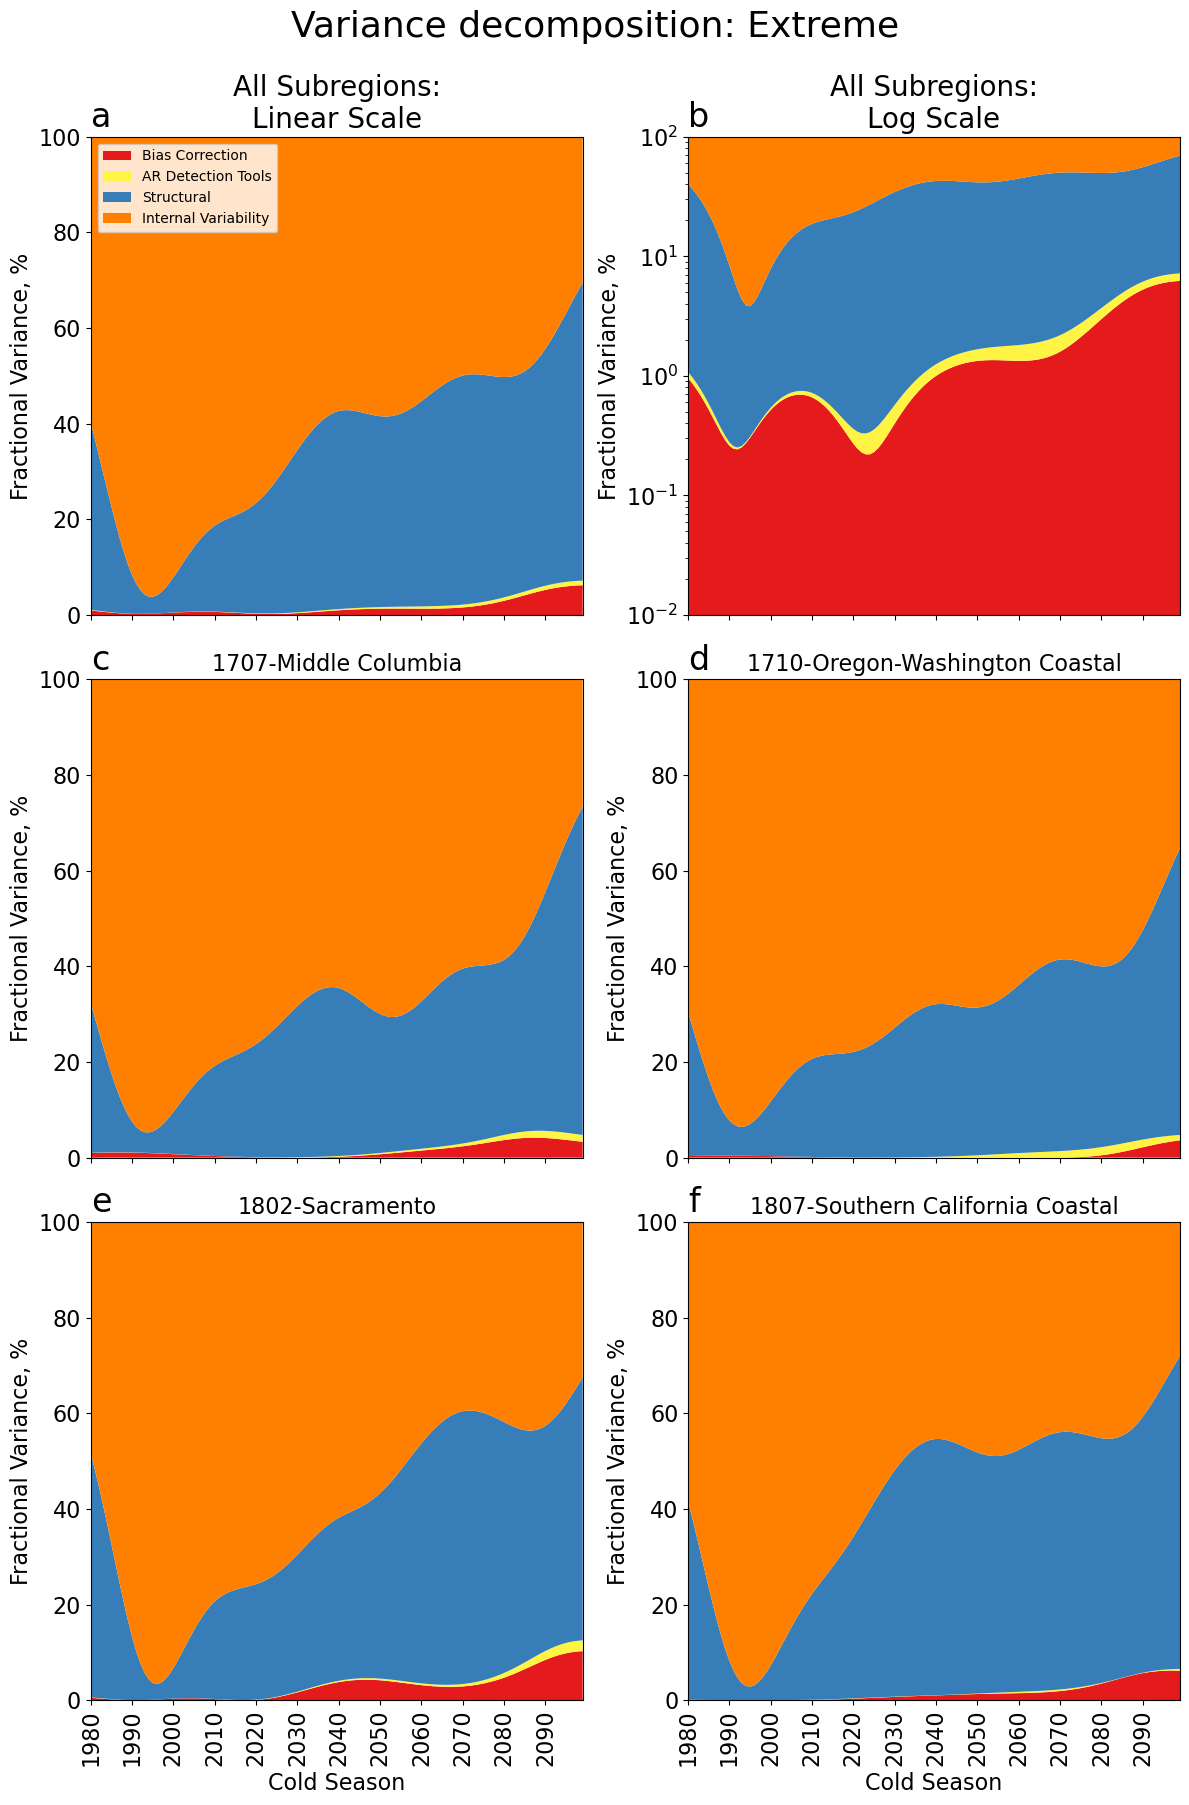

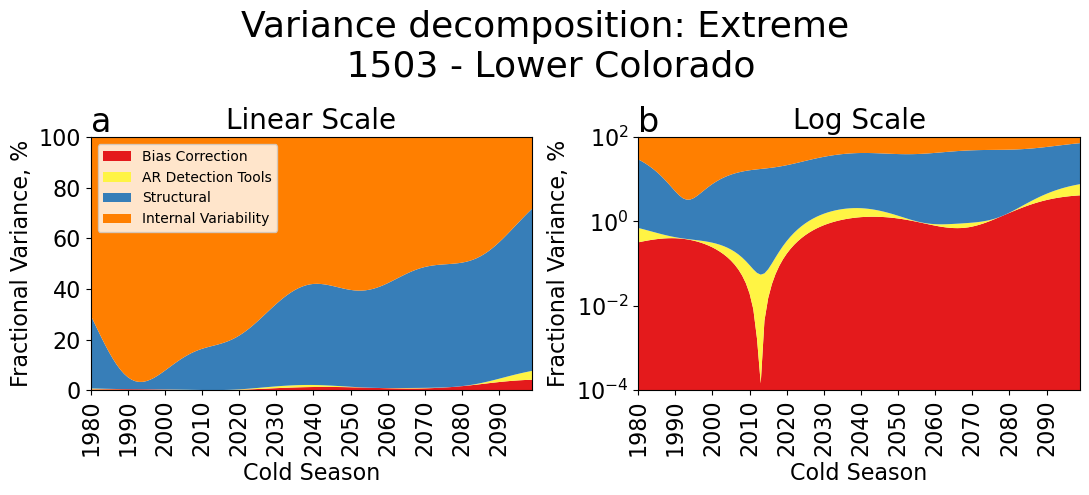

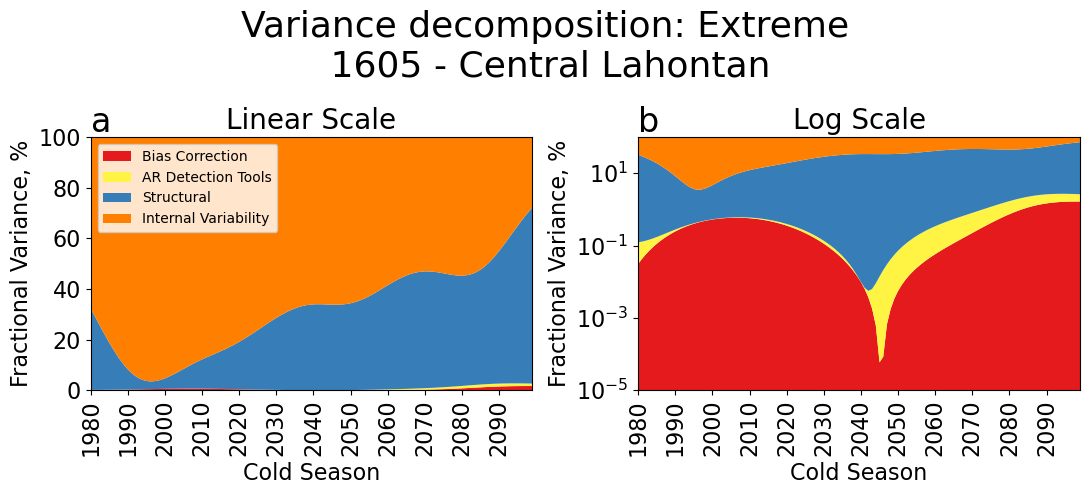

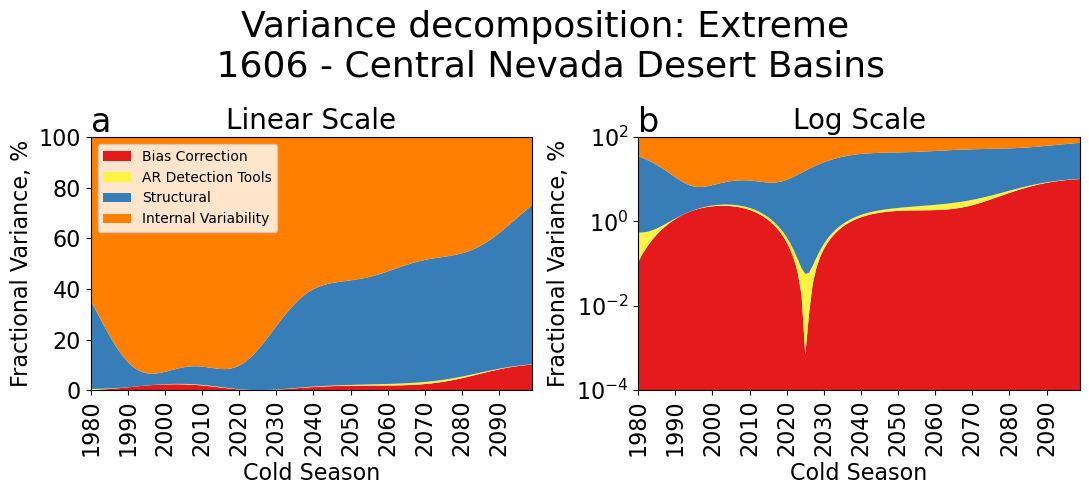

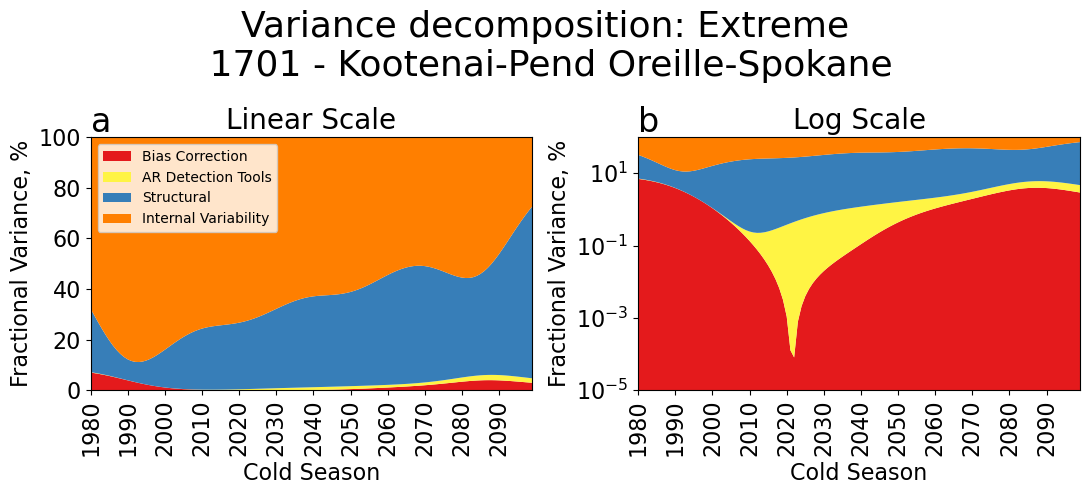

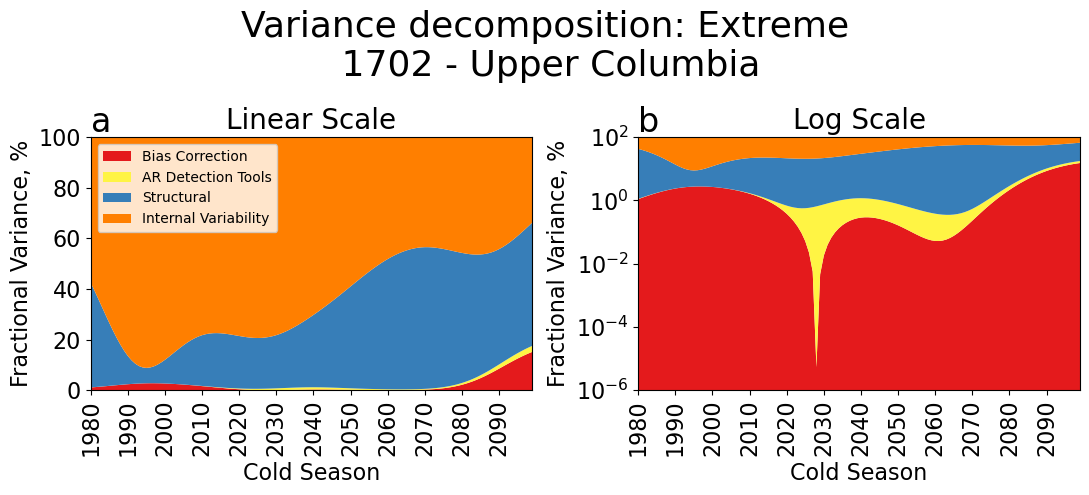

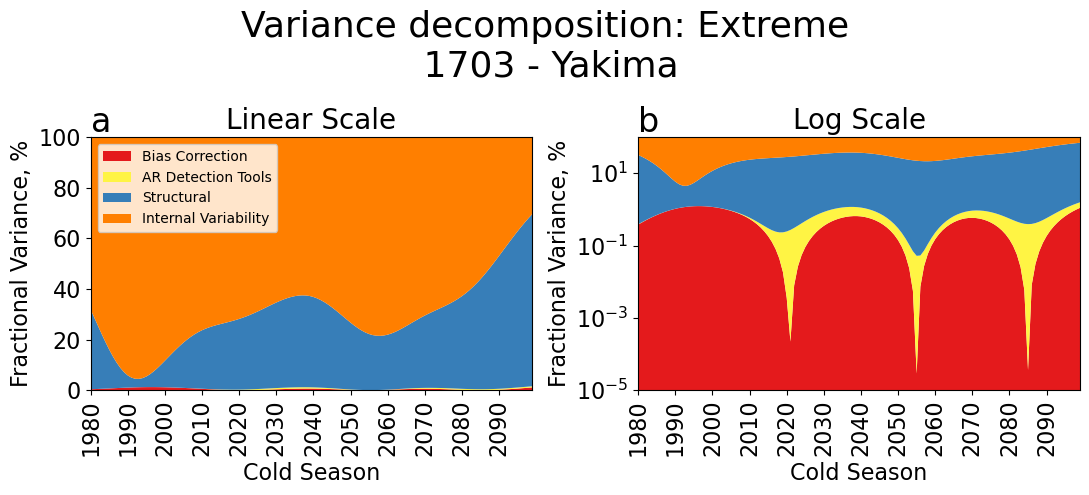

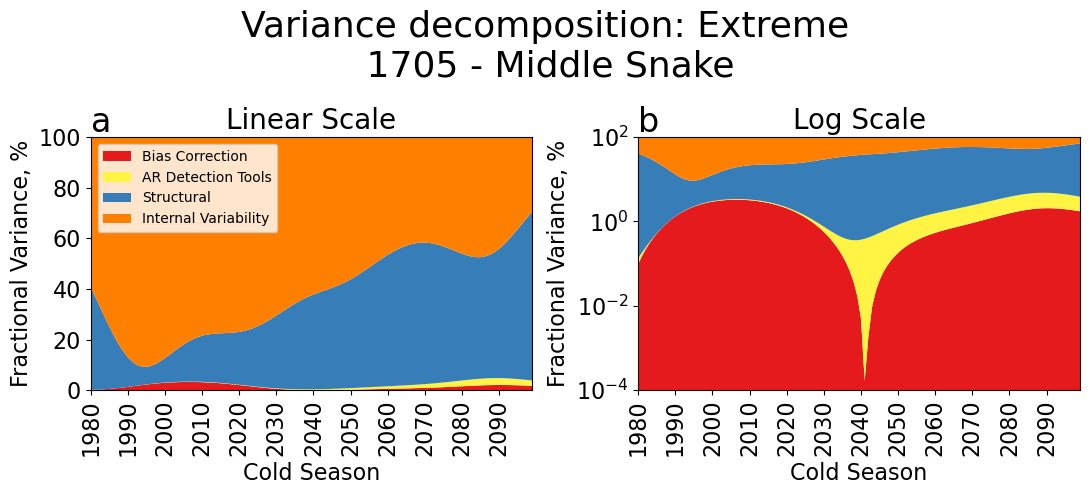

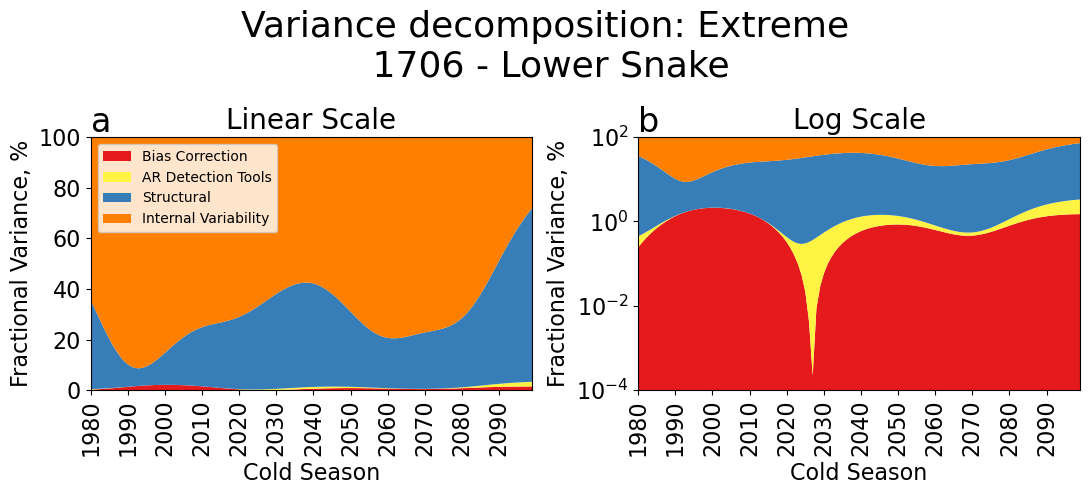

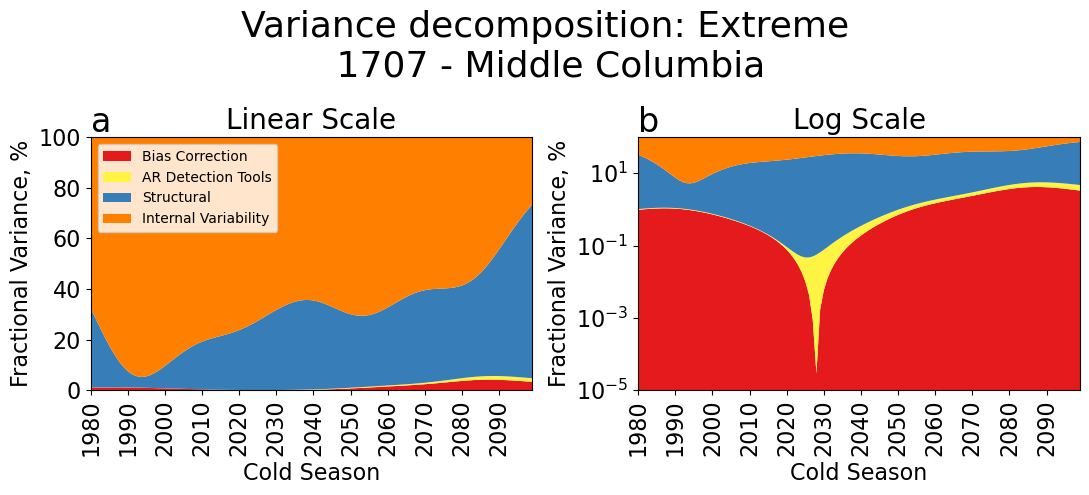

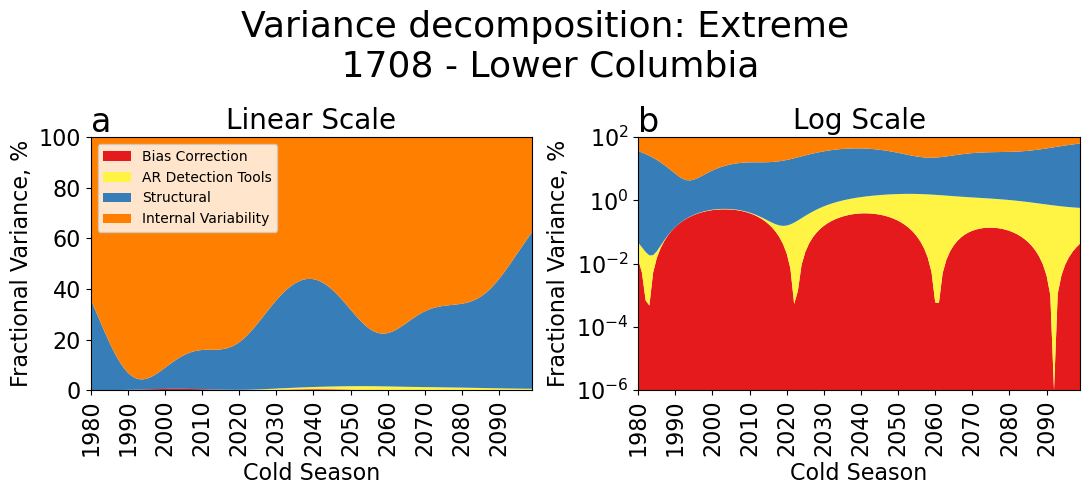

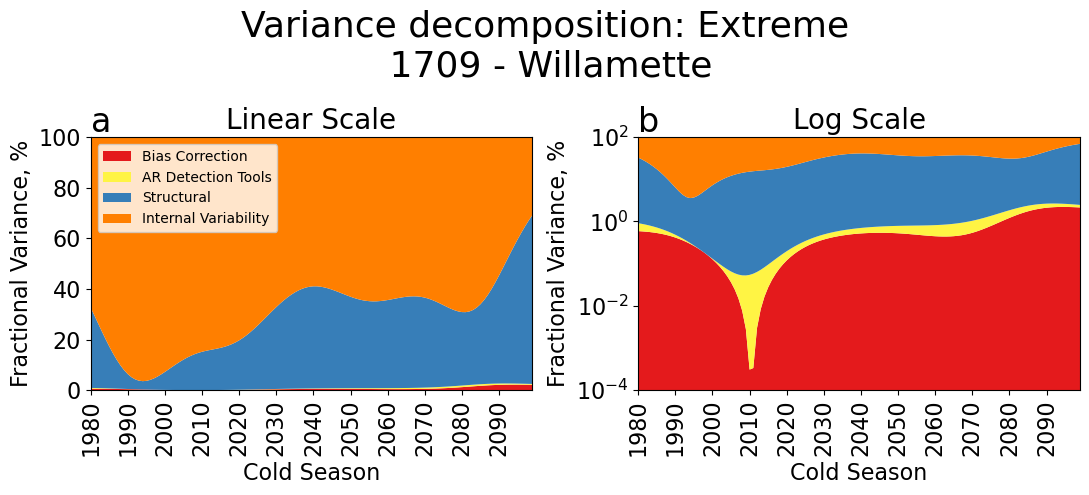

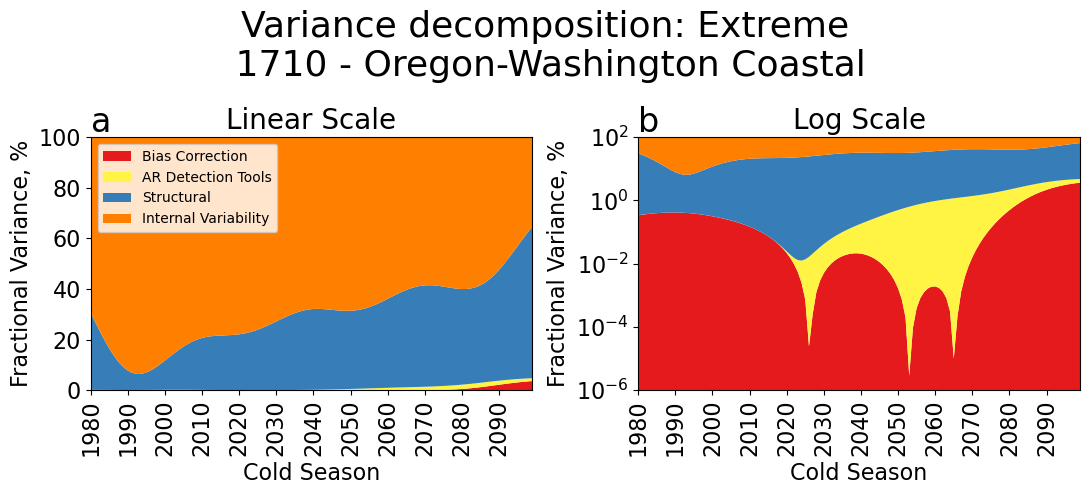

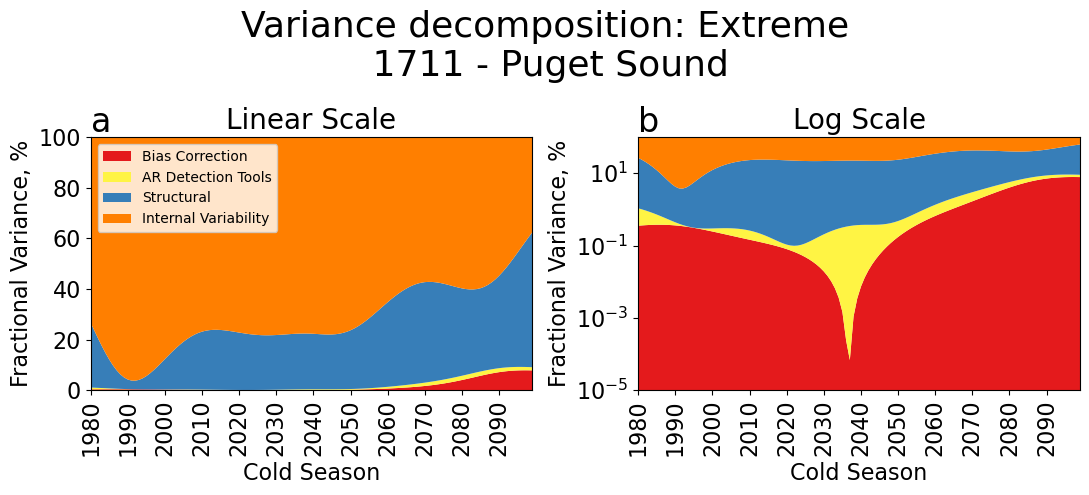

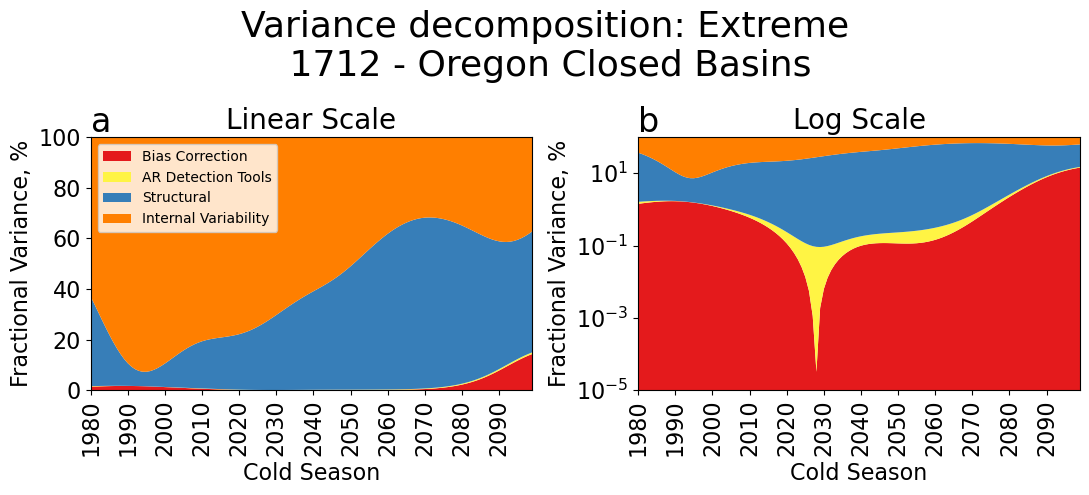

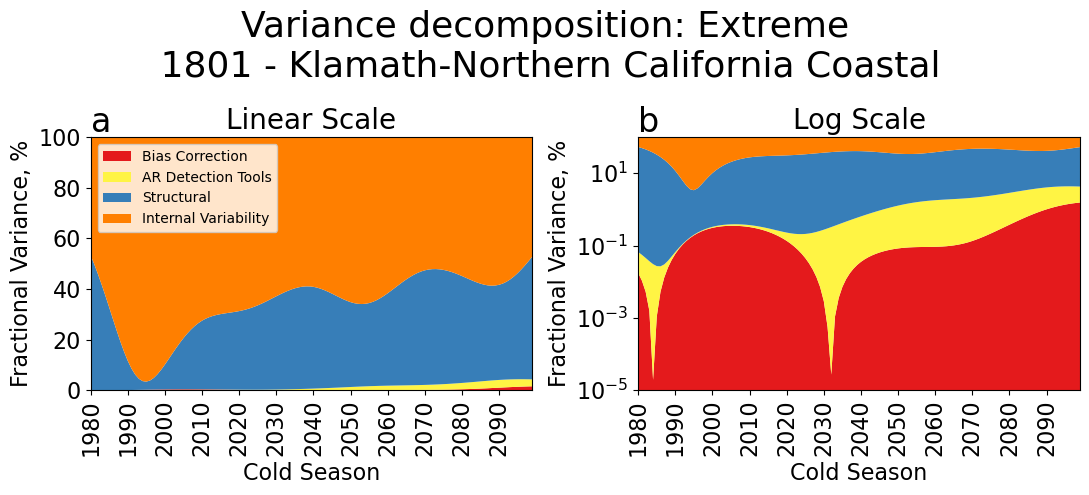

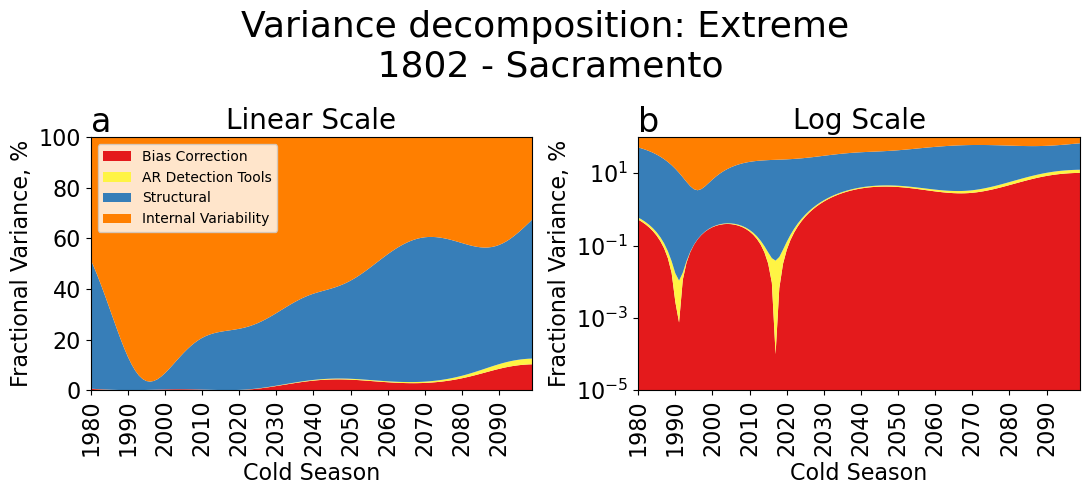

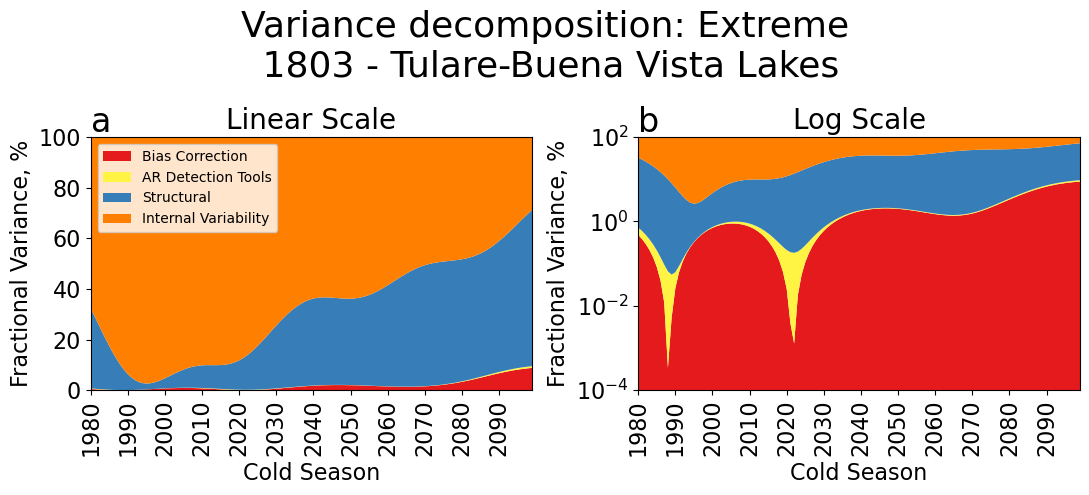

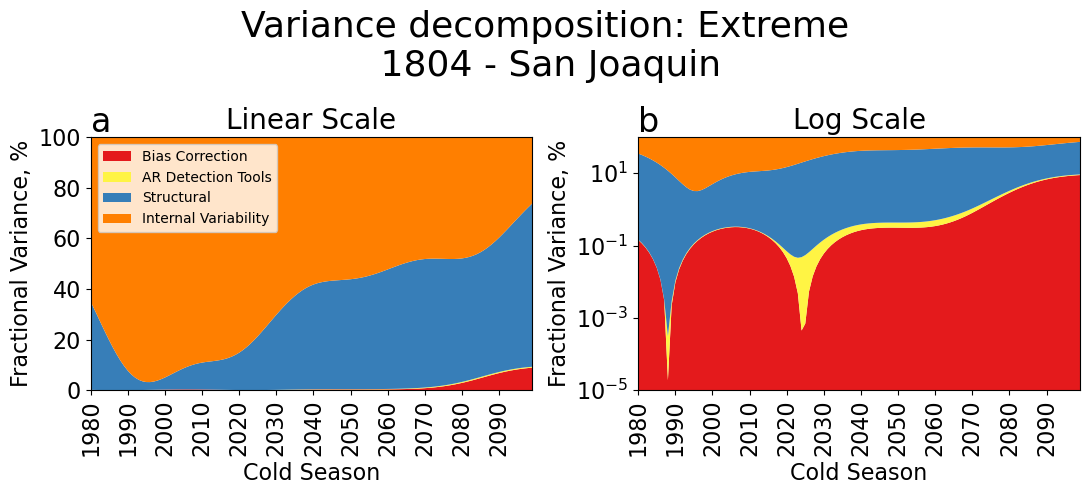

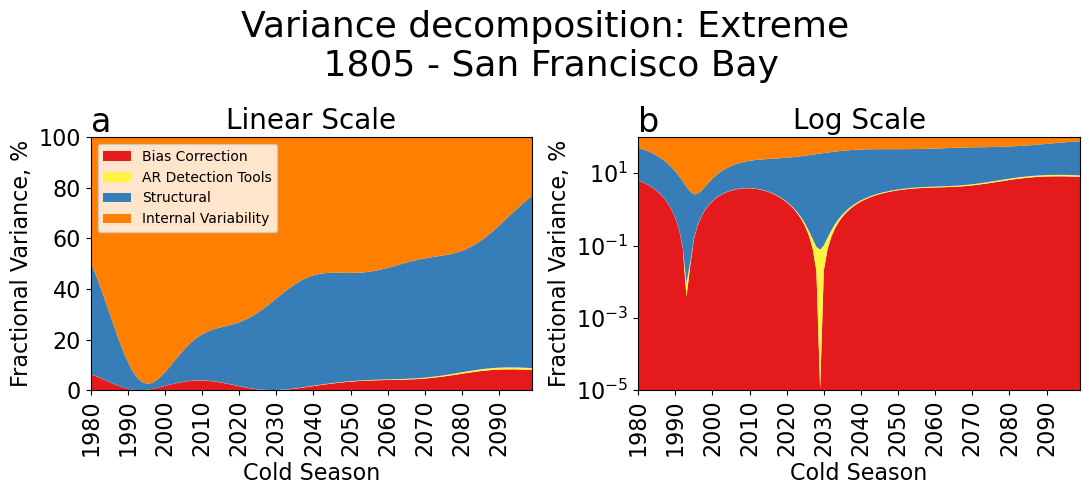

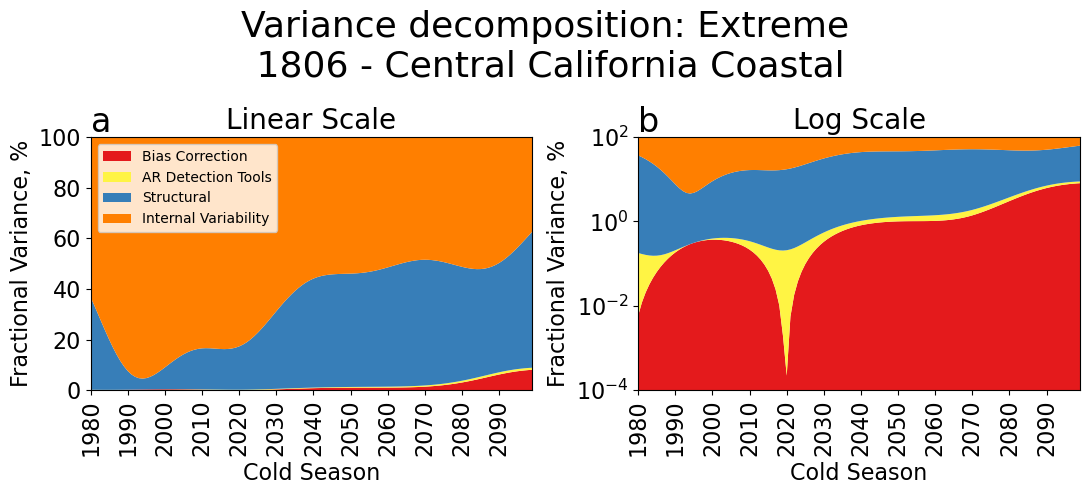

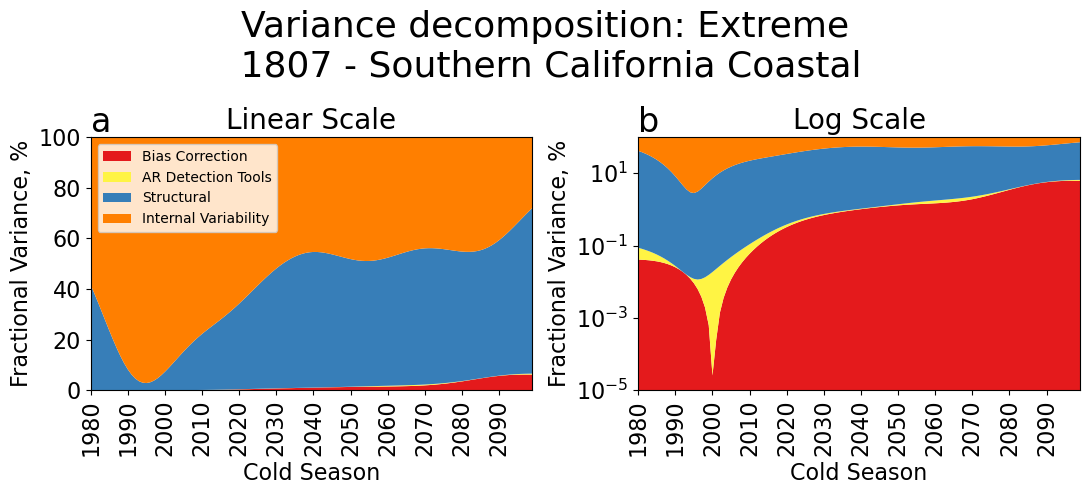

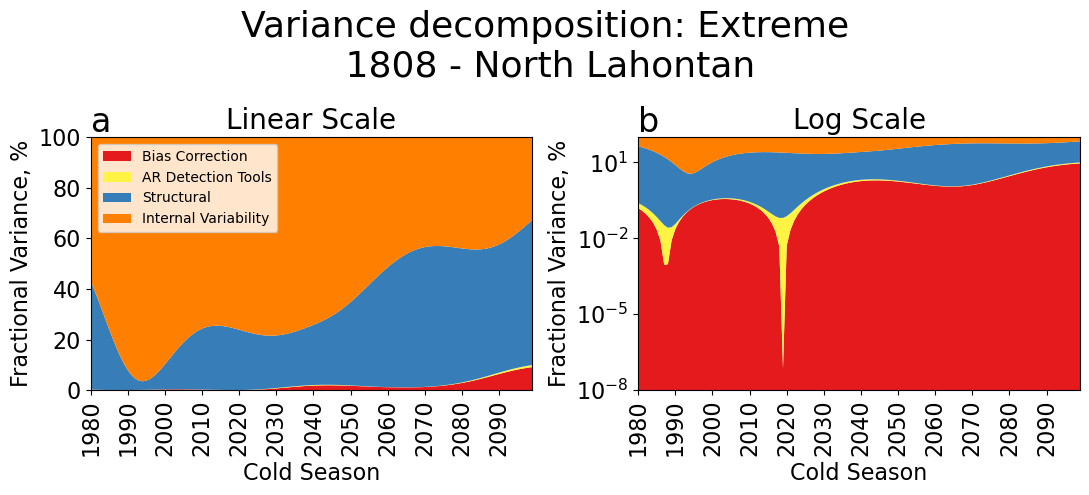

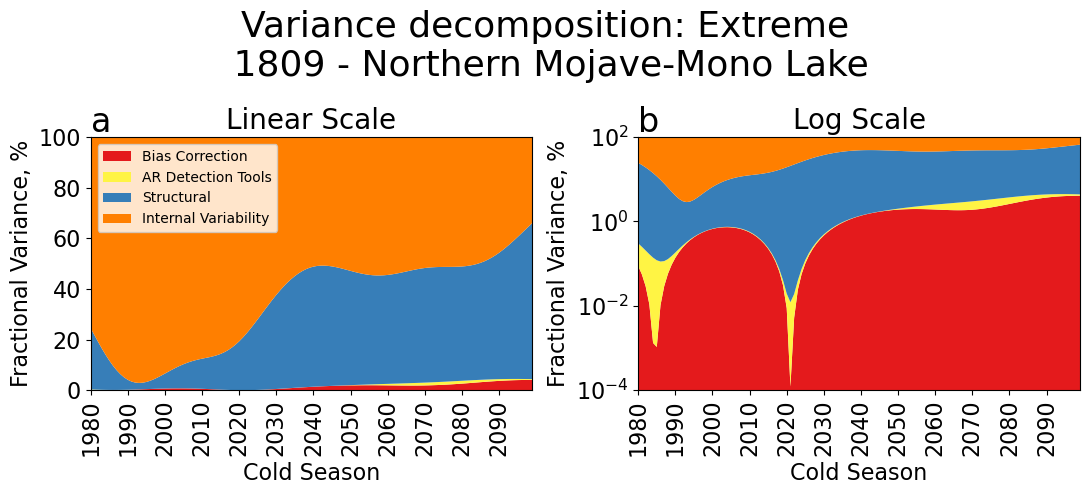

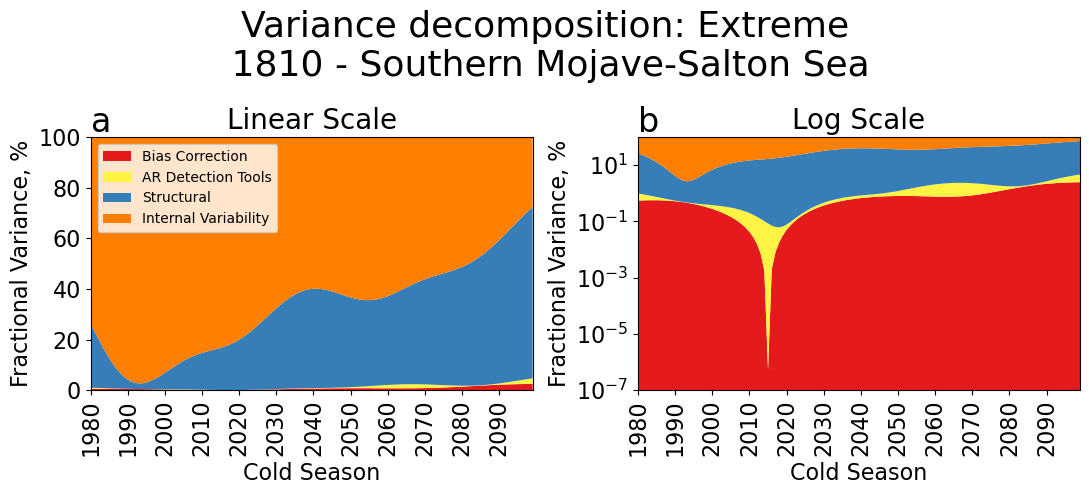

In [1]:
# Import appropriate modules
import xarray as xa
import numpy as np
from glob import glob
import pandas as pd
import geopandas as gpd
import cftime
import regionmask
import sys
import scipy
import patsy
from sklearn.linear_model import LinearRegression
from scipy.interpolate import CubicSpline
import matplotlib.pyplot as plt
import string

# Load geopandas databases
wus_db = gpd.read_file('../watersheds_WUS.geojson', driver='GeoJSON')[['huc4', 'name', 'geometry']]


# Dimension names
dim0_name = "watershed_id"
dim1_name = "year"
dim2_name = "model"
dim3_name = "bc"
dim4_name = "ARDT"

B_overall = np.zeros(120)
M_overall = np.zeros(120)
A_overall = np.zeros(120)
V_overall = np.zeros(120)
T_overall = np.zeros(120)


# Load command-line parameters
watershed_idxs = np.arange(1, 25) 
f7, a7 = plt.subplots(3, 2, figsize=(12, 18))
for watershed_idx in watershed_idxs:
    # Create the sub-dataset
    ds_pre = xa.open_dataset('mean_arrays/prec_extrememean_annually.nc').sel(watershed_idx=watershed_idx)
    ds = ds_pre.rename({'cold_season': 'year', 'prec_mean': 'Y', 'model_idx': 'model', 'bc_idx': 'bc', 'ardt_idx': 'ARDT'})
    ds['Ymean'] = ds.Y.sel(year=slice(1980, 2014)).mean(dim='year')
    ds['Ytilde'] = ds.Y - ds.Ymean
    
    # Model 1
    Ytilde_ravel = np.array([])
    years_ravel = np.array([])
    
    for m in ds.model:
        for b in ds.bc:
            for a in ds.ARDT:
                ds_sel = ds.sel(model=m, bc=b, ARDT=a)
                Ytilde_ravel = np.concatenate((Ytilde_ravel, ds_sel.Ytilde.values))
                years_ravel = np.concatenate((years_ravel, ds_sel.year.values))
                Ytilde_ravel = np.nan_to_num(Ytilde_ravel, nan=1.0)
                
    
    spline = patsy.cr(years_ravel, df=4, constraints='center')
    model = LinearRegression().fit(spline, Ytilde_ravel)
    y_hat = model.predict(spline)
    
    ds['Yhat1'] = (['year'], y_hat[:120])
    
    # Model 2: Each BC configuration gets its own spline
    ds['Yhat2'] = (['year', 'bc'], np.empty((len(ds.year),len(ds.bc))))
    
    for b in ds.bc:
        ds_bc = ds.sel(bc=b)
        Ytilde_ravel = np.array([])
        years_ravel = np.array([])
        for m in ds.model:
            for a in ds.ARDT:
                ds_sel = ds_bc.sel(model=m, ARDT=a)
                Ytilde_ravel = np.concatenate((Ytilde_ravel, ds_sel.Ytilde.values))
                years_ravel = np.concatenate((years_ravel, ds_sel.year.values))
                Ytilde_ravel = np.nan_to_num(Ytilde_ravel, nan=1.0)
    
        spline = patsy.cr(years_ravel, df=4, constraints='center')
    
    
        model = LinearRegression().fit(spline, Ytilde_ravel)
        y_hat = model.predict(spline)
        ds.Yhat2.loc[{'bc':b}] = y_hat[:120]
    
    # Model 3: Each Model configuration gets its own spline
    ds['Yhat3'] = (['year', 'model'], np.empty((len(ds.year),len(ds.model))))
    
    for m in ds.model:
        ds_model = ds.sel(model=m)
        Ytilde_ravel = np.array([])
        years_ravel = np.array([])
        for b in ds.bc:
            for a in ds.ARDT:
                ds_sel = ds_model.sel(bc=b, ARDT=a)
                Ytilde_ravel = np.concatenate((Ytilde_ravel, ds_sel.Ytilde.values))
                years_ravel = np.concatenate((years_ravel, ds_sel.year.values))
                Ytilde_ravel = np.nan_to_num(Ytilde_ravel, nan=1.0)
    
        spline = patsy.cr(years_ravel, df=4, constraints='center')
    
    
        model = LinearRegression().fit(spline, Ytilde_ravel)
        y_hat = model.predict(spline)
        ds.Yhat3.loc[{'model':m}] = y_hat[:120]
    
    # Model 4: Each ARDT gets its own spline
    ds['Yhat4'] = (['year', 'ARDT'], np.empty((len(ds.year),len(ds.ARDT))))
    
    for a in ds.ARDT:
        ds_ardt = ds.sel(ARDT=a)
        Ytilde_ravel = np.array([])
        years_ravel = np.array([])
        for m in ds.model:
            for b in ds.bc:
                ds_sel = ds_ardt.sel(model=m, bc=b)
                Ytilde_ravel = np.concatenate((Ytilde_ravel, ds_sel.Ytilde.values))
                years_ravel = np.concatenate((years_ravel, ds_sel.year.values))
                Ytilde_ravel = np.nan_to_num(Ytilde_ravel, nan=1.0)
    
        spline = patsy.cr(years_ravel, df=4, constraints='center')
    
    
        model = LinearRegression().fit(spline, Ytilde_ravel)
        y_hat = model.predict(spline)
        ds.Yhat4.loc[{'ARDT':a}] = y_hat[:120]
    
    # Model 5: Each configuration gets its own spline
    ds['Yhat5'] = (['year', 'model', 'bc', 'ARDT'], np.empty((len(ds.year),len(ds.model),len(ds.bc),len(ds.ARDT))))
    
    
    for m in ds.model:
        for b in ds.bc:
            for a in ds.ARDT:
                ds_sel = ds.sel(model=m, bc=b, ARDT=a)
                Ytilde_ravel = np.array([])
                years_ravel = np.array([])
                Ytilde_ravel = np.concatenate((Ytilde_ravel, ds_sel.Ytilde.values))
                years_ravel = np.concatenate((years_ravel, ds_sel.year.values))
                Ytilde_ravel = np.nan_to_num(Ytilde_ravel, nan=1.0)
    
                spline = patsy.cr(years_ravel, df=4, constraints='center')
            
            
                model = LinearRegression().fit(spline, Ytilde_ravel)
                y_hat = model.predict(spline)
                ds.Yhat5.loc[{'model':m,'bc':b,'ARDT':a}] = y_hat[:120]
                
    # For models with missing dimensions, duplicate arrays to match that of model 5.
    ds_bcst, _ = xa.broadcast(ds[['Yhat2', 'Yhat3', 'Yhat4']], ds.Y)

    # BC, Structural, and ARDT variance calculation
    Bt = np.square(ds_bcst.Yhat2-ds.Yhat1).sum(dim=['bc','model','ARDT'])
    Mt = np.square(ds_bcst.Yhat3-ds.Yhat1).sum(dim=['bc','model','ARDT'])
    At = np.square(ds_bcst.Yhat4-ds.Yhat1).sum(dim=['bc','model','ARDT'])

    #Internal variability calculation
    e = ds.Ytilde - ds.Yhat5
    etilde = e.rolling(year=10, min_periods=1).mean()
    V = np.square(etilde).sum()/120

    # Total variability
    T = Bt + Mt + At + V

    B_overall = np.add(B_overall, Bt)
    M_overall = np.add(M_overall, Mt)
    A_overall = np.add(A_overall, At)
    V_overall = np.add(V_overall, np.full(120, V))
    T_overall = np.add(T_overall, T)

    # Fractional variability
    Bt_frac = np.divide(Bt, T)*100
    Mt_frac = np.divide(Mt, T)*100
    At_frac = np.divide(At, T)*100
    V_frac = np.divide(V, T)*100

    # Plot the fractions over time
    f6, a6 = plt.subplots(1, 2, figsize=(11,5))

    # This accounts for all subregions but Fig. 11 shows all combined plus the four of focus in the main paper
    wname = wus_db.loc[watershed_idx-1]['name']
    wnamestring = wname.replace(" ", "_")
    wid = wus_db.loc[watershed_idx-1]['huc4']
    
    uncert_dict = {"Bias Correction": Bt_frac.values, "AR Detection Tools": At_frac.values, "Structural": Mt_frac.values, "Internal Variability": V_frac.values}
    uncert_colors = ['#e41a1c', '#fff444', '#377eb8', '#ff7f00']
    
    a6[0].stackplot(np.arange(1980, 2100), uncert_dict.values(), labels=uncert_dict.keys(), alpha=1, 
                 colors=uncert_colors, edgecolor=None)
    a6[1].stackplot(np.arange(1980, 2100), uncert_dict.values(), labels=uncert_dict.keys(), alpha=1, 
                 colors=uncert_colors, edgecolor=None)
    a6[1].set_yscale('log')
    for i in range(2):
        a6[i].set_xlim([1980, 2099])
        a6[i].set_xticks(np.arange(1980, 2100, 10))
        a6[i].set_xticklabels(np.arange(1980, 2100, 10), rotation=90, fontsize=16)
        if i==0:
            a6[i].set_ylim([0,100])
        else:
            log_min = np.min(Bt_frac)
            a6[i].set_ylim(10 ** np.floor(np.log10(log_min)), 100)
        a6[i].tick_params(axis='y', labelsize=16)
        a6[i].set_ylabel('Fractional Variance, %', fontsize=16)
        if i == 0:
            a6[i].legend(loc='upper left')
        a6[i].set_xlabel('Cold Season', fontsize=16)
        figtitle = 'Linear Scale' if i==0 else 'Log Scale'
        a6[i].set_xlabel('Cold Season', fontsize=16)
        a6[i].set_title(figtitle, fontsize=20)
        a6[i].text(0, 1.02, string.ascii_lowercase[i], transform=a6[i].transAxes, fontsize=24)
    f6.suptitle(f'Variance decomposition: Extreme\n {wid} - {wname}', fontsize=26)

    focus = ['1707', '1710', '1802', '1807']
    if str(wid) in focus:
        idx = focus.index(str(wid))
        a7[idx//2+1, idx%2].stackplot(np.arange(1980, 2100), uncert_dict.values(), labels=uncert_dict.keys(), alpha=1, 
                 colors=uncert_colors, edgecolor=None)
        a7[idx//2+1, idx%2].set_xlim([1980, 2099])
        a7[idx//2+1, idx%2].set_xticks(np.arange(1980, 2100, 10))
        if idx>=2:
            a7[idx//2+1, idx%2].set_xticklabels(np.arange(1980, 2100, 10), rotation=90, fontsize=16)
            a7[idx//2+1, idx%2].set_xlabel('Cold Season', fontsize=16)
        else:
            a7[idx//2+1, idx%2].set_xticklabels([""]*12)
        a7[idx//2+1, idx%2].set_ylim([0,100])
        a7[idx//2+1, idx%2].tick_params(axis='y', labelsize=16)
        a7[idx//2+1, idx%2].set_ylabel('Fractional Variance, %', fontsize=16)
        a7[idx//2+1, idx%2].set_title(f'{wid}-{wname}', fontsize=16)
    f6.tight_layout()
    f6.savefig(f'/glade/work/tcorrie/ARdata/Figures/watersheds/variancedecomps/variancedecomposition_prec_watershed_{wid}-{wnamestring}_extremes.png', bbox_inches='tight')
    f6.savefig(f'/glade/work/tcorrie/ARdata/Figures/JoC/variancedecomposition_prec_watershed_{wid}-{wnamestring}_supp_extremes.png', bbox_inches='tight')
f7.suptitle(f'Variance decomposition: Extreme', fontsize=26, y=1.0)


B_frac_overall = np.divide(B_overall, T_overall)*100
M_frac_overall = np.divide(M_overall, T_overall)*100
A_frac_overall = np.divide(A_overall, T_overall)*100
V_frac_overall = np.divide(V_overall, T_overall)*100



uncert_dict_wall = {"Bias Correction": B_frac_overall.values, "AR Detection Tools": A_frac_overall.values, "Structural": M_frac_overall.values, "Internal Variability": V_frac_overall.values}
a7[0, 0].stackplot(np.arange(1980, 2100), uncert_dict_wall.values(), labels=uncert_dict_wall.keys(), alpha=1, 
                colors=uncert_colors, edgecolor=None)
a7[0, 1].stackplot(np.arange(1980, 2100), uncert_dict_wall.values(), labels=uncert_dict_wall.keys(), alpha=1, 
                colors=uncert_colors, edgecolor=None)
a7[0, 1].set_yscale('log')
for i in range(2):
    a7[0,i].set_xlim([1980, 2099])
    a7[0,i].set_xticks(np.arange(1980, 2100, 10))
    a7[0,i].set_xticklabels([""]*12)
    a7[0,i].set_ylim([0,100]) if i==0 else a7[0,i].set_ylim([1e-2,100])
    a7[0,i].tick_params(axis='y', labelsize=16)
    a7[0,i].set_ylabel('Fractional Variance, %', fontsize=16)
    figtitle = 'All Subregions:\nLinear Scale' if i==0 else 'All Subregions:\nLog Scale'
    a7[0,i].set_title(figtitle, fontsize=20)
a7[0,0].legend(loc='upper left')
for i in range(6):
    a7[i//2, i%2].text(0, 1.02, string.ascii_lowercase[i], transform=a7[i//2, i%2].transAxes, fontsize=24)
f7.tight_layout()
f7.savefig(f'/glade/work/tcorrie/ARdata/Figures/JoC/variancedecomposition_prec_allplusfourwatersheds_extreme.png', bbox_inches='tight')